# 03 — Iris Dataset: Exploratory Data Analysis (EDA)

**Datheon | Machine Learning & Data Science Internship | Task 01**

This notebook performs dataset loading, data-quality inspection, descriptive analysis, statistical exploration, and professional static/interactive visualizations.

**Scope:** EDA only. No machine-learning models are trained. The Iris dataset has no date/time field, so this notebook does not fabricate time-series data.

**Outputs:** PNG charts, interactive Plotly HTML charts, CSV reports, and a text insights report. The notebook does **not** create or save any `.ipynb` files and does not overwrite the raw dataset.


## 1. Environment and libraries

In [1]:
# If needed, uncomment and run:
# %pip install pandas numpy matplotlib seaborn plotly scipy

import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (11, 6),
    "figure.dpi": 120,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "legend.fontsize": 9,
})

print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Python: 3.11.9
Pandas: 3.0.5
NumPy: 2.4.6


## 2. Locate project folders and load the original dataset

Expected raw file: `Task-01-Iris-Classification/data/raw/iris.data`. The path detection checks the notebook's current directory and its parents.

In [2]:
current = Path.cwd()
PROJECT_ROOT = next(
    (p for p in [current, *current.parents] if (p / "data" / "raw" / "iris.data").exists()),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find data/raw/iris.data from the current folder or its parents. "
        "Place the original UCI file at Task-01-Iris-Classification/data/raw/iris.data."
    )

DATA_FILE = PROJECT_ROOT / "data" / "raw" / "iris.data"
OUTPUT_ROOT = PROJECT_ROOT / "outputs"
FIGURES_DIR = OUTPUT_ROOT / "figures"
INTERACTIVE_DIR = OUTPUT_ROOT / "interactive"
REPORTS_DIR = OUTPUT_ROOT / "reports"

for folder in (FIGURES_DIR, INTERACTIVE_DIR, REPORTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

columns = ["sepal_length", "sepal_width", "petal_length", "petal_width", "species"]
df = pd.read_csv(DATA_FILE, header=None, names=columns, na_values=["", "?", "NA", "NaN"])

for col in columns[:4]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df["species"] = df["species"].astype("string").str.strip()

print("Project root:", PROJECT_ROOT)
print("Dataset file:", DATA_FILE)
print("Shape:", df.shape)
display(df.head())

Project root: D:\Datheon-ML-Data-Science-Internship\Task-01-Iris-Classification
Dataset file: D:\Datheon-ML-Data-Science-Internship\Task-01-Iris-Classification\data\raw\iris.data
Shape: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.100,3.500,1.400,0.200,Iris-setosa
1,4.900,3.000,1.400,0.200,Iris-setosa
2,4.700,3.200,1.300,0.200,Iris-setosa
3,4.600,3.100,1.500,0.200,Iris-setosa
4,5.000,3.600,1.400,0.200,Iris-setosa


## 3. Dataset structure and quality

In [3]:
print("Dataset information")
df.info()

quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(),
})
quality["duplicate_rows_in_dataset"] = int(df.duplicated().sum())
display(quality)
quality.to_csv(REPORTS_DIR / "data_quality_report.csv")

print("Duplicate rows:", df.duplicated().sum())
print("Missing cells:", df.isna().sum().sum())
print("Unexpected species:", sorted(set(df["species"].dropna().unique()) -
                                     {"Iris-setosa", "Iris-versicolor", "Iris-virginica"}))
print("Non-positive numeric measurements:")
display((df[columns[:4]] <= 0).sum().rename("count").to_frame())

Dataset information
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    string 
dtypes: float64(4), string(1)
memory usage: 8.0 KB


,dtype,missing_count,missing_percent,unique_values,duplicate_rows_in_dataset
sepal_length,float64,0,0.000,35,3
sepal_width,float64,0,0.000,23,3
petal_length,float64,0,0.000,43,3
petal_width,float64,0,0.000,22,3
species,string,0,0.000,3,3


Duplicate rows: 3
Missing cells: 0
Unexpected species: []
Non-positive numeric measurements:


,count
sepal_length,0
sepal_width,0
petal_length,0
petal_width,0


## 4. Descriptive statistics

In [4]:
numeric_features = columns[:4]
descriptive = df[numeric_features].describe().T
descriptive["range"] = descriptive["max"] - descriptive["min"]
descriptive["coefficient_of_variation"] = descriptive["std"] / descriptive["mean"]
display(descriptive)
descriptive.to_csv(REPORTS_DIR / "descriptive_statistics.csv")

species_summary = df.groupby("species")[numeric_features].agg(
    ["count", "mean", "median", "std", "min", "max"]
)
display(species_summary)
species_summary.to_csv(REPORTS_DIR / "species_statistical_summary.csv")

,count,mean,std,min,25%,50%,75%,max,range,coefficient_of_variation
sepal_length,150.000,5.843,0.828,4.300,5.100,5.800,6.400,7.900,3.600,0.142
sepal_width,150.000,3.054,0.434,2.000,2.800,3.000,3.300,4.400,2.400,0.142
petal_length,150.000,3.759,1.764,1.000,1.600,4.350,5.100,6.900,5.900,0.469
petal_width,150.000,1.199,0.763,0.100,0.300,1.300,1.800,2.500,2.400,0.637


sepal_length                                sepal_width        \
                       count  mean median   std   min   max       count  mean   
species                                                                         
Iris-setosa               50 5.006  5.000 0.352 4.300 5.800          50 3.418   
Iris-versicolor           50 5.936  5.900 0.516 4.900 7.000          50 2.770   
Iris-virginica            50 6.588  6.500 0.636 4.900 7.900          50 2.974   

                                         petal_length                     \
                median   std   min   max        count  mean median   std   
species                                                                    
Iris-setosa      3.400 0.381 2.300 4.400           50 1.464  1.500 0.174   
Iris-versicolor  2.800 0.314 2.000 3.400           50 4.260  4.350 0.470   
Iris-virginica   3.000 0.322 2.200 3.800           50 5.552  5.550 0.552   

                            petal_width                                 
                  min   max       count  mean median   std   min   max  
species                                                                 
Iris-setosa     1.000 1.900          50 0.244  0.200 0.107 0.100 0.600  
Iris-versicolor 3.000 5.100          50 1.326  1.300 0.198 1.000 1.800  
Iris-virginica  4.500 6.900          50 2.026  2.000 0.275 1.400 2.500

## 5. Species distribution

,species,count,percentage
0,Iris-setosa,50,33.333
1,Iris-versicolor,50,33.333
2,Iris-virginica,50,33.333


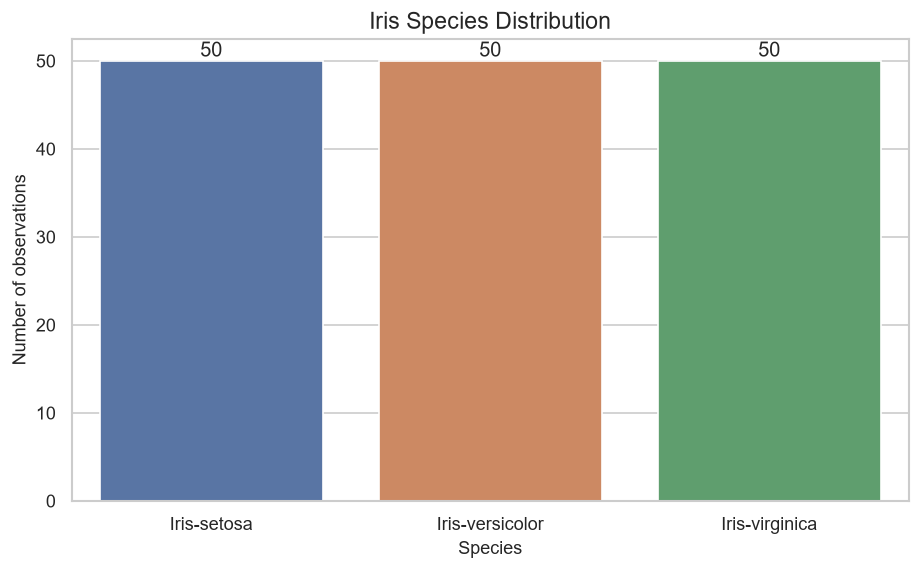

In [5]:
species_counts = df["species"].value_counts(dropna=False).rename_axis("species").reset_index(name="count")
species_counts["percentage"] = species_counts["count"] / len(df) * 100
display(species_counts)
species_counts.to_csv(REPORTS_DIR / "species_distribution.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=species_counts, x="species", y="count", hue="species", legend=False, ax=ax)
ax.set(title="Iris Species Distribution", xlabel="Species", ylabel="Number of observations")
for container in ax.containers:
    ax.bar_label(container)
fig.savefig(FIGURES_DIR / "species_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. Feature distributions

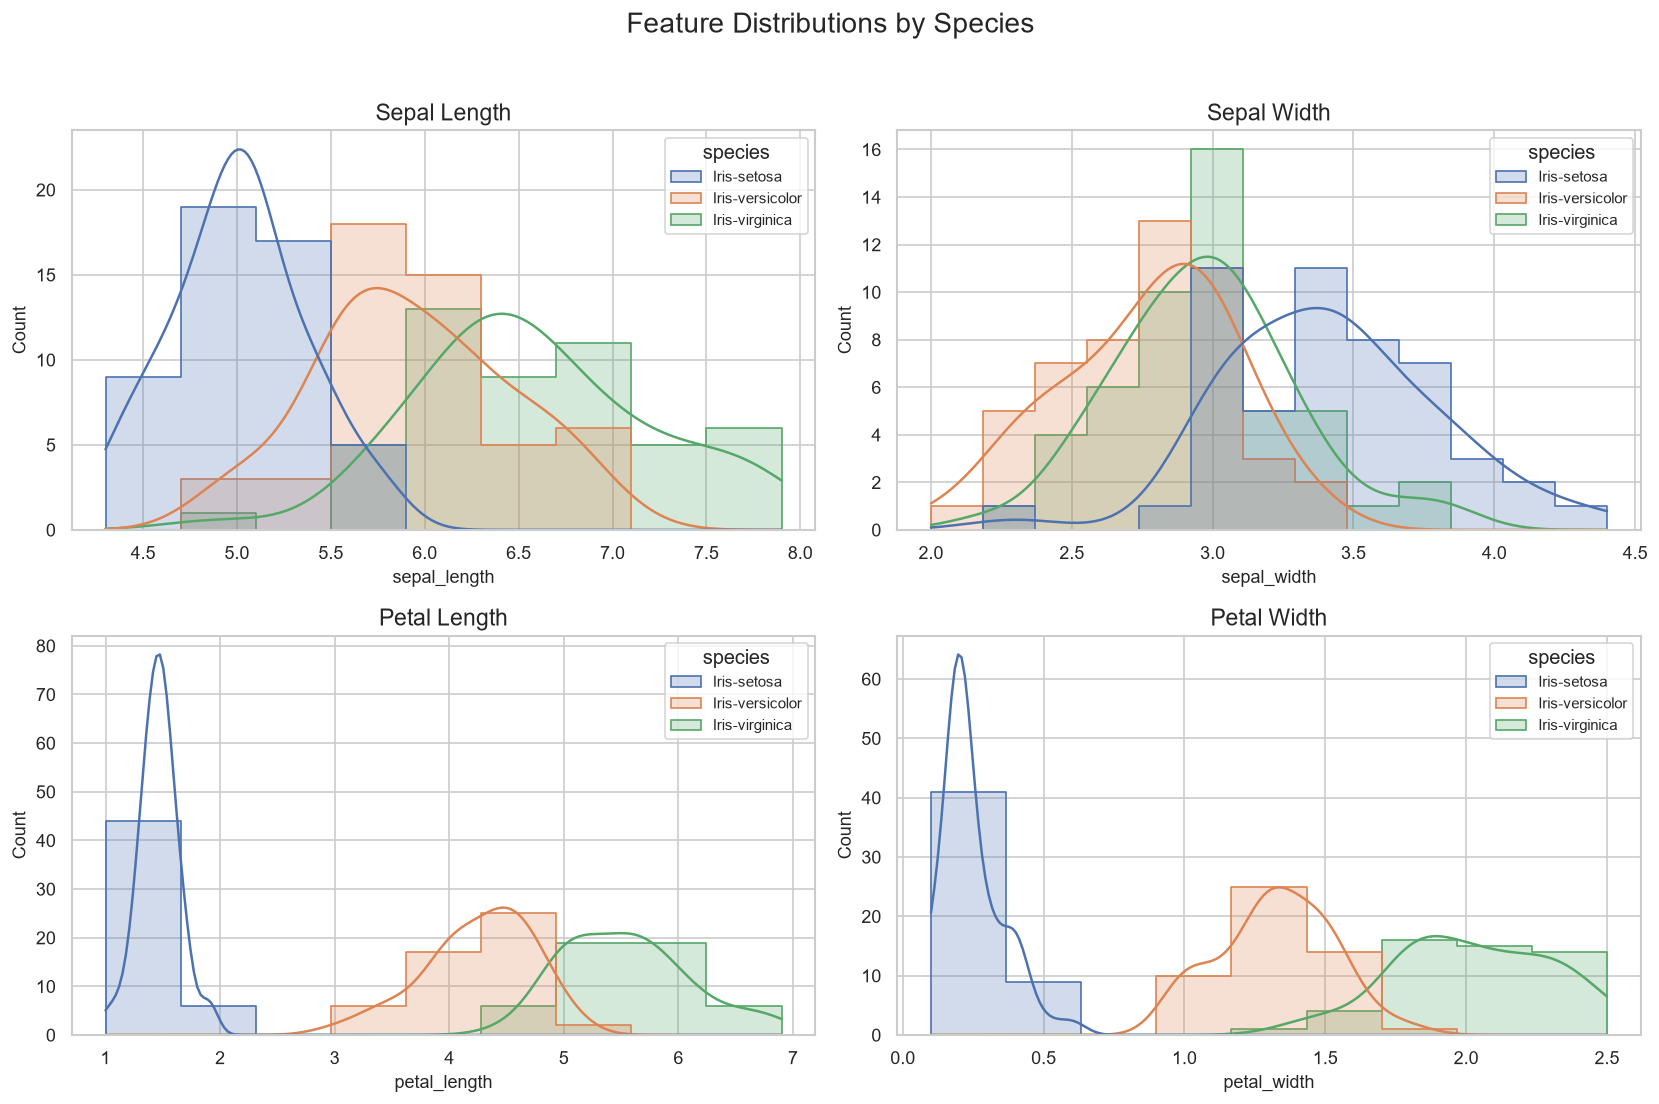

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, feature in zip(axes.flat, numeric_features):
    sns.histplot(data=df, x=feature, hue="species", kde=True,
                 element="step", common_norm=False, ax=ax)
    ax.set_title(feature.replace("_", " ").title())
fig.suptitle("Feature Distributions by Species", fontsize=17, y=1.02)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "feature_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Boxplots and violin plots

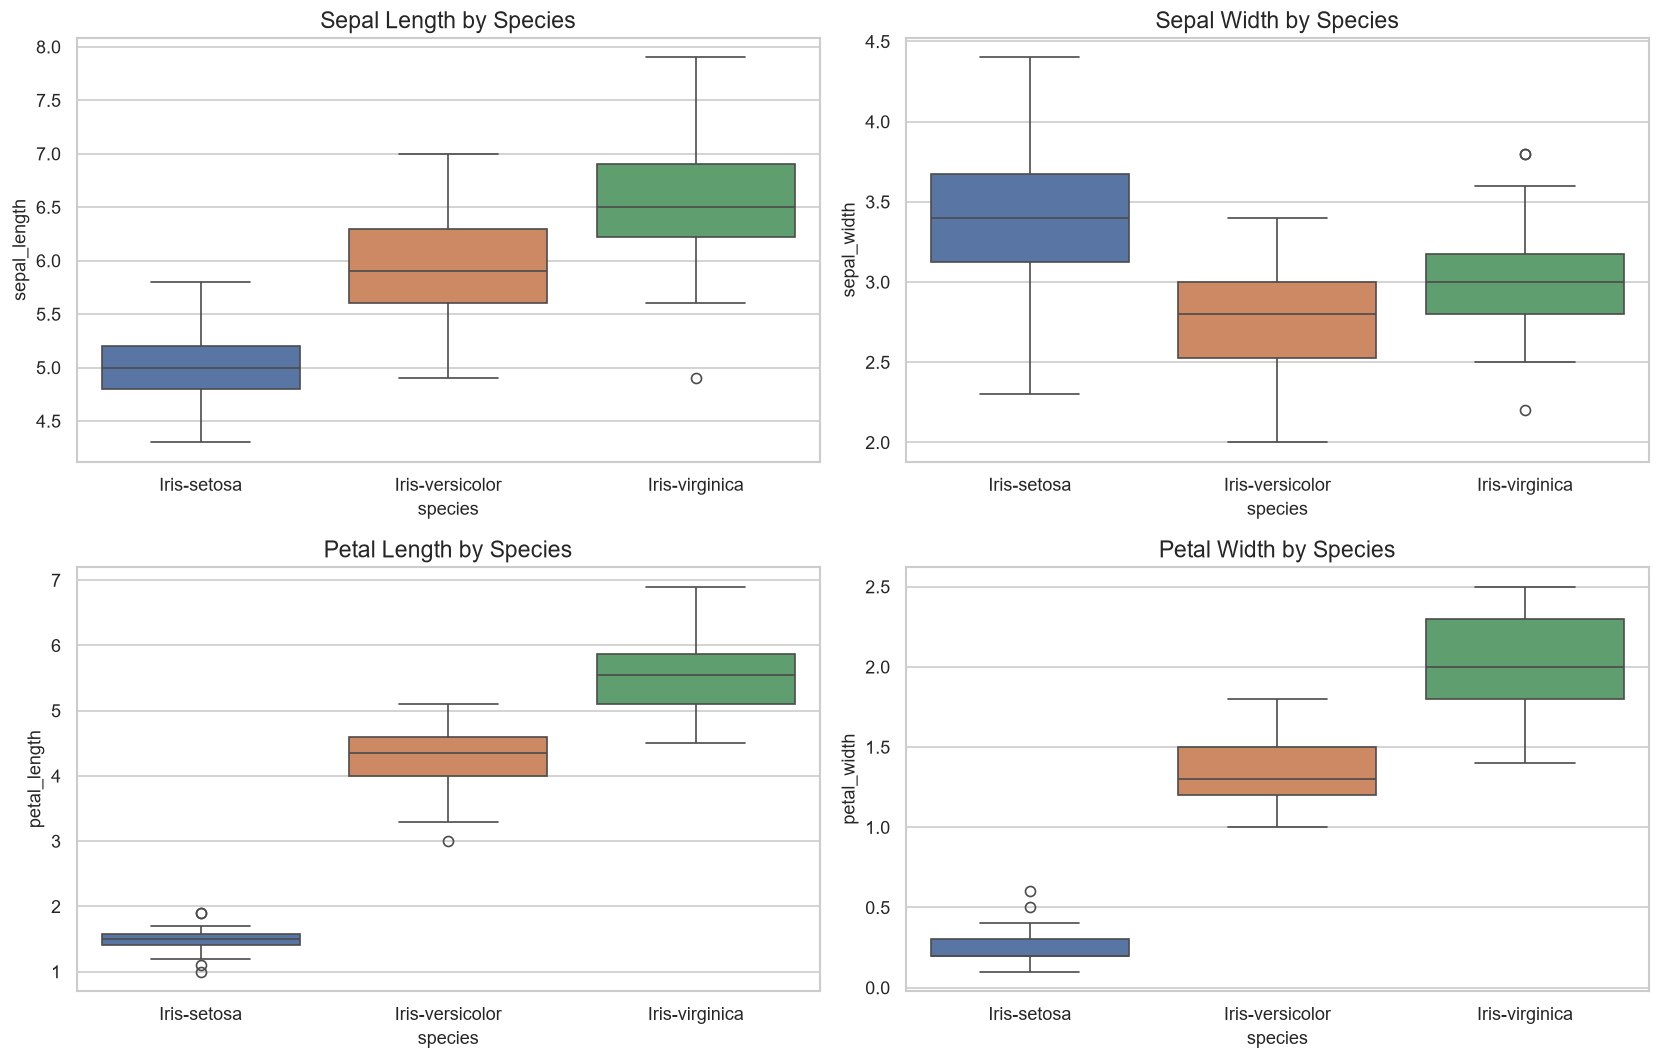

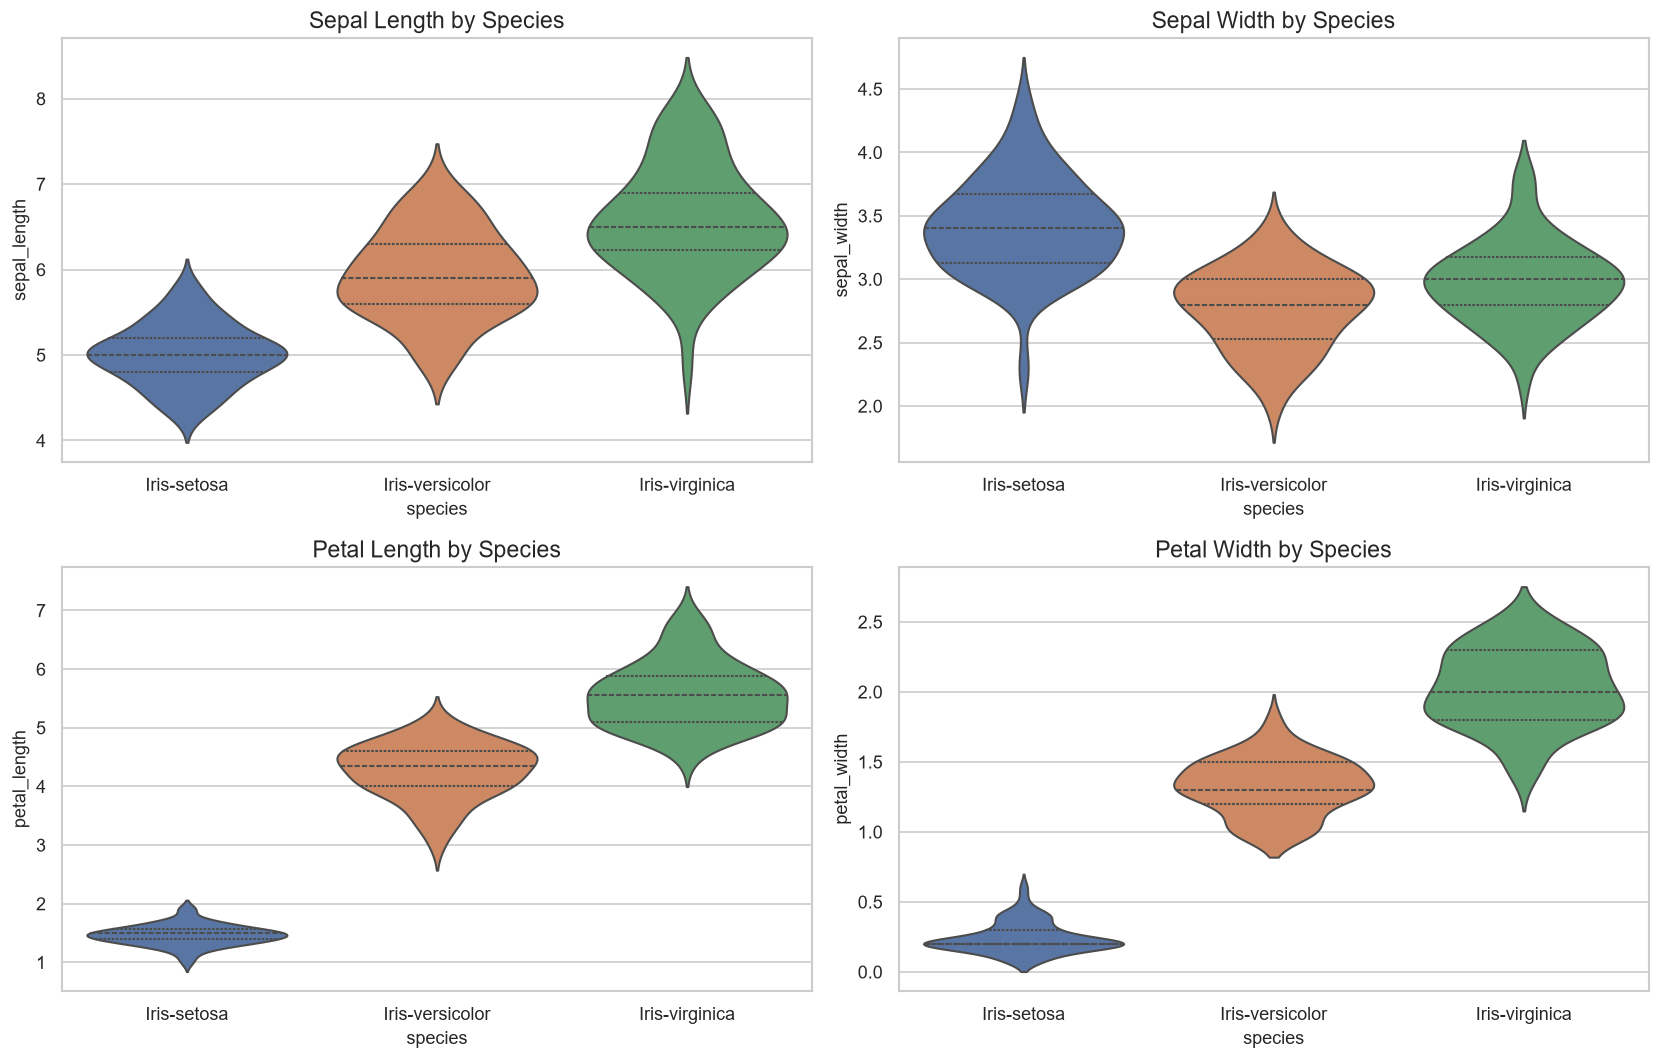

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, feature in zip(axes.flat, numeric_features):
    sns.boxplot(data=df, x="species", y=feature, hue="species", legend=False, ax=ax)
    ax.set_title(f"{feature.replace('_', ' ').title()} by Species")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "boxplots.png", dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, feature in zip(axes.flat, numeric_features):
    sns.violinplot(data=df, x="species", y=feature, hue="species",
                   legend=False, inner="quartile", ax=ax)
    ax.set_title(f"{feature.replace('_', ' ').title()} by Species")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "violin_plots.png", dpi=300, bbox_inches="tight")
plt.show()

## 8. Pairwise relationships

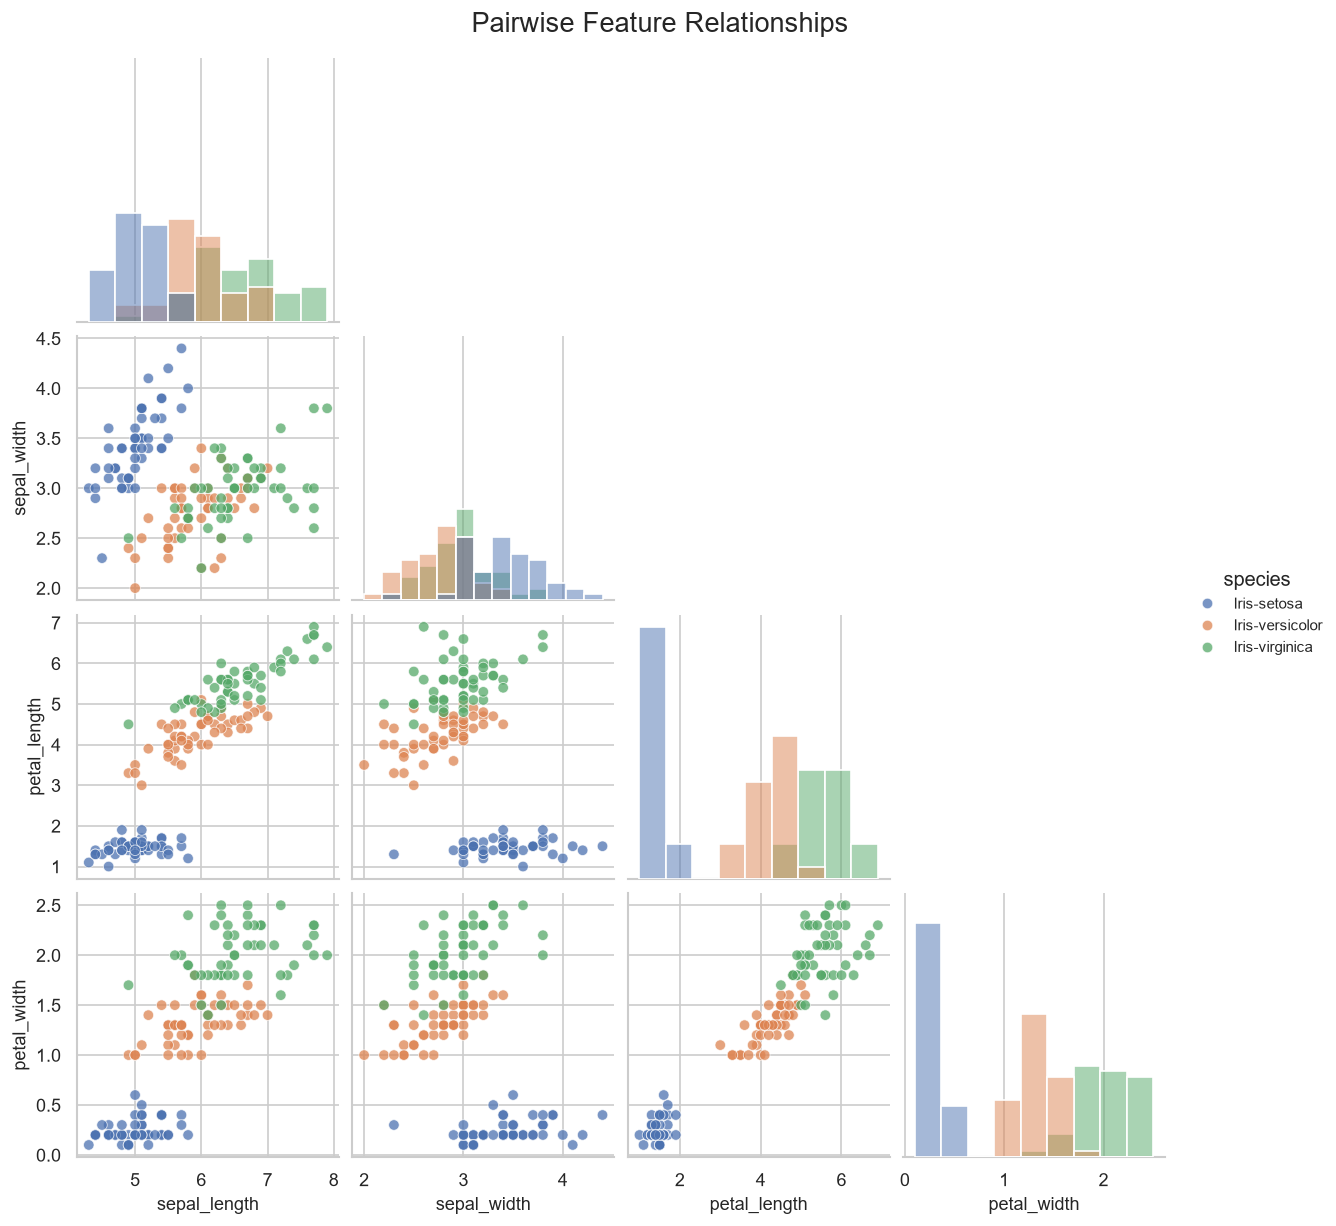

In [8]:
pair_grid = sns.pairplot(
    df, vars=numeric_features, hue="species",
    diag_kind="hist", corner=True,
    plot_kws={"alpha": 0.75, "s": 40}
)
pair_grid.fig.suptitle("Pairwise Feature Relationships", y=1.02, fontsize=16)
pair_grid.savefig(FIGURES_DIR / "pairplot.png", dpi=300, bbox_inches="tight")
plt.show()

## 9. Correlation analysis

,sepal_length,sepal_width,petal_length,petal_width
sepal_length,1.000,-0.109,0.872,0.818
sepal_width,-0.109,1.000,-0.421,-0.357
petal_length,0.872,-0.421,1.000,0.963
petal_width,0.818,-0.357,0.963,1.000


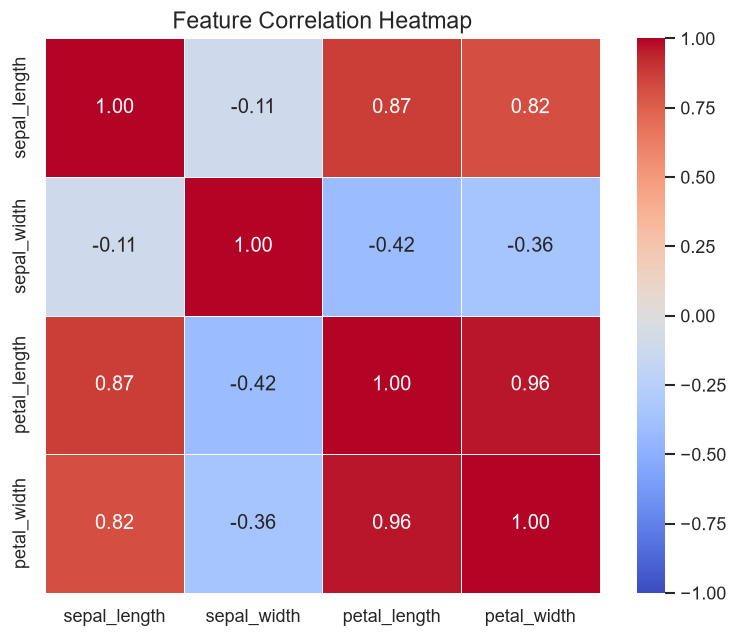

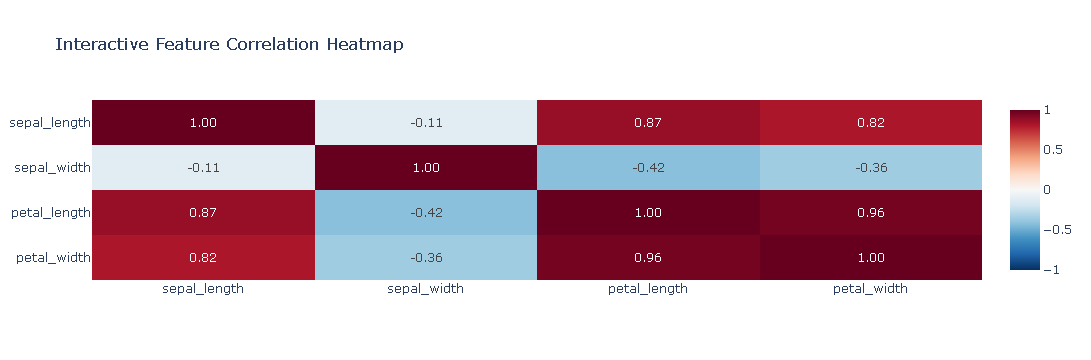

In [9]:
correlation = df[numeric_features].corr()
display(correlation)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax)
ax.set_title("Feature Correlation Heatmap")
fig.savefig(FIGURES_DIR / "correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

fig = px.imshow(
    correlation, text_auto=".2f", color_continuous_scale="RdBu_r",
    zmin=-1, zmax=1, aspect="auto",
    title="Interactive Feature Correlation Heatmap",
    template="plotly_white"
)
fig.write_html(INTERACTIVE_DIR / "correlation_analysis.html")
fig.show()

## 10. Species-wise feature comparisons

,species,sepal_length,sepal_width,petal_length,petal_width
0,Iris-setosa,5.006,3.418,1.464,0.244
1,Iris-versicolor,5.936,2.770,4.260,1.326
2,Iris-virginica,6.588,2.974,5.552,2.026


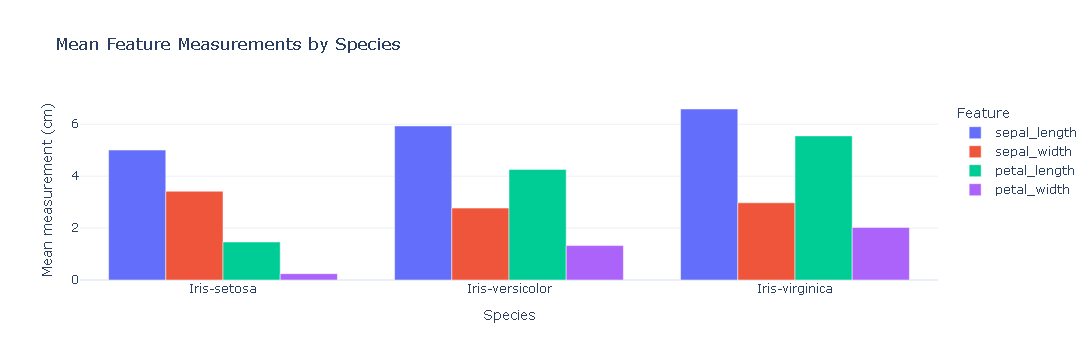

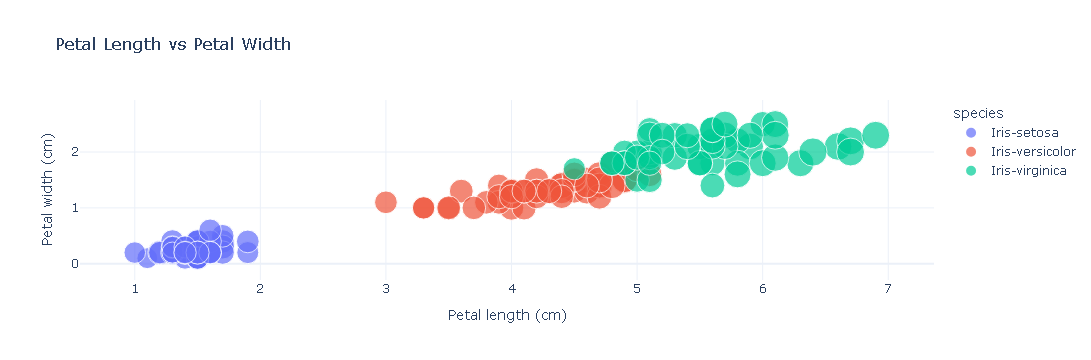

In [10]:
species_means = df.groupby("species")[numeric_features].mean().reset_index()
display(species_means)

fig = px.bar(
    species_means, x="species", y=numeric_features, barmode="group",
    title="Mean Feature Measurements by Species",
    labels={"species": "Species", "value": "Mean measurement (cm)", "variable": "Feature"},
    template="plotly_white"
)
fig.write_html(INTERACTIVE_DIR / "species_comparison.html")
fig.show()

fig = px.scatter(
    df, x="petal_length", y="petal_width", color="species",
    size="sepal_length", hover_data=numeric_features,
    title="Petal Length vs Petal Width",
    labels={"petal_length": "Petal length (cm)", "petal_width": "Petal width (cm)"},
    template="plotly_white"
)
fig.write_html(INTERACTIVE_DIR / "petal_relationship.html")
fig.show()

## 11. Interactive distributions

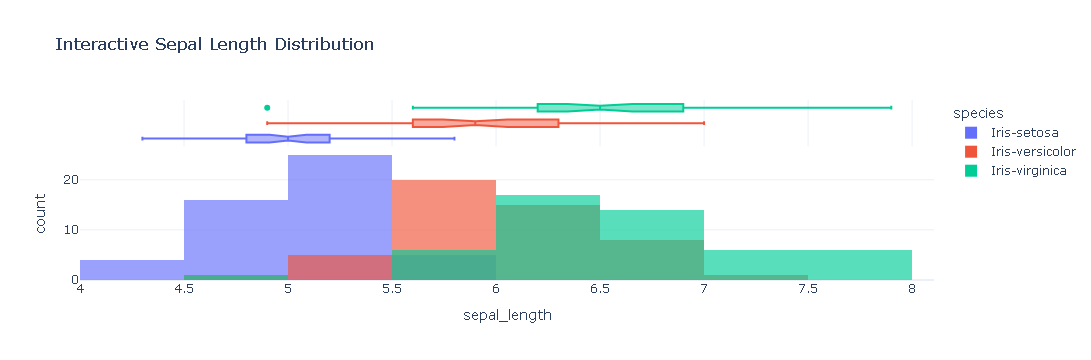

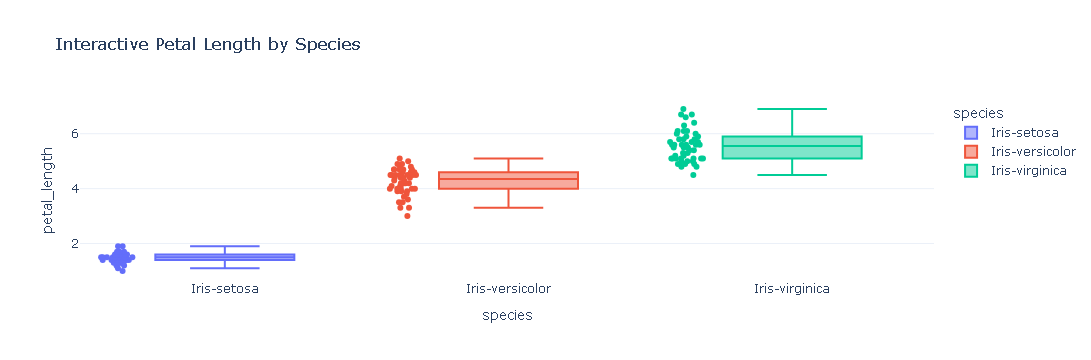

In [11]:
fig = px.histogram(
    df, x="sepal_length", color="species", marginal="box",
    barmode="overlay", opacity=0.65,
    title="Interactive Sepal Length Distribution",
    template="plotly_white"
)
fig.write_html(INTERACTIVE_DIR / "sepal_length_distribution.html")
fig.show()

fig = px.box(
    df, x="species", y="petal_length", color="species", points="all",
    title="Interactive Petal Length by Species",
    template="plotly_white"
)
fig.write_html(INTERACTIVE_DIR / "petal_length_boxplot.html")
fig.show()

## 12. Outlier screening using IQR

IQR flags are screening indicators only. This notebook does not automatically remove outliers.

In [12]:
outlier_rows = []
for feature in numeric_features:
    q1 = df[feature].quantile(0.25)
    q3 = df[feature].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (df[feature] < lower) | (df[feature] > upper)
    outlier_rows.append({
        "feature": feature, "q1": q1, "q3": q3, "iqr": iqr,
        "lower_bound": lower, "upper_bound": upper,
        "potential_outlier_count": int(mask.sum())
    })
outlier_report = pd.DataFrame(outlier_rows)
display(outlier_report)
outlier_report.to_csv(REPORTS_DIR / "outlier_screening_report.csv", index=False)

,feature,q1,q3,iqr,lower_bound,upper_bound,potential_outlier_count
0,sepal_length,5.100,6.400,1.300,3.150,8.350,0
1,sepal_width,2.800,3.300,0.500,2.050,4.050,4
2,petal_length,1.600,5.100,3.500,-3.650,10.350,0
3,petal_width,0.300,1.800,1.500,-1.950,4.050,0


## 13. Species-wise mean trends with confidence intervals

These are categorical species comparisons, not time-series trends. The Iris dataset does not contain dates or timestamps.

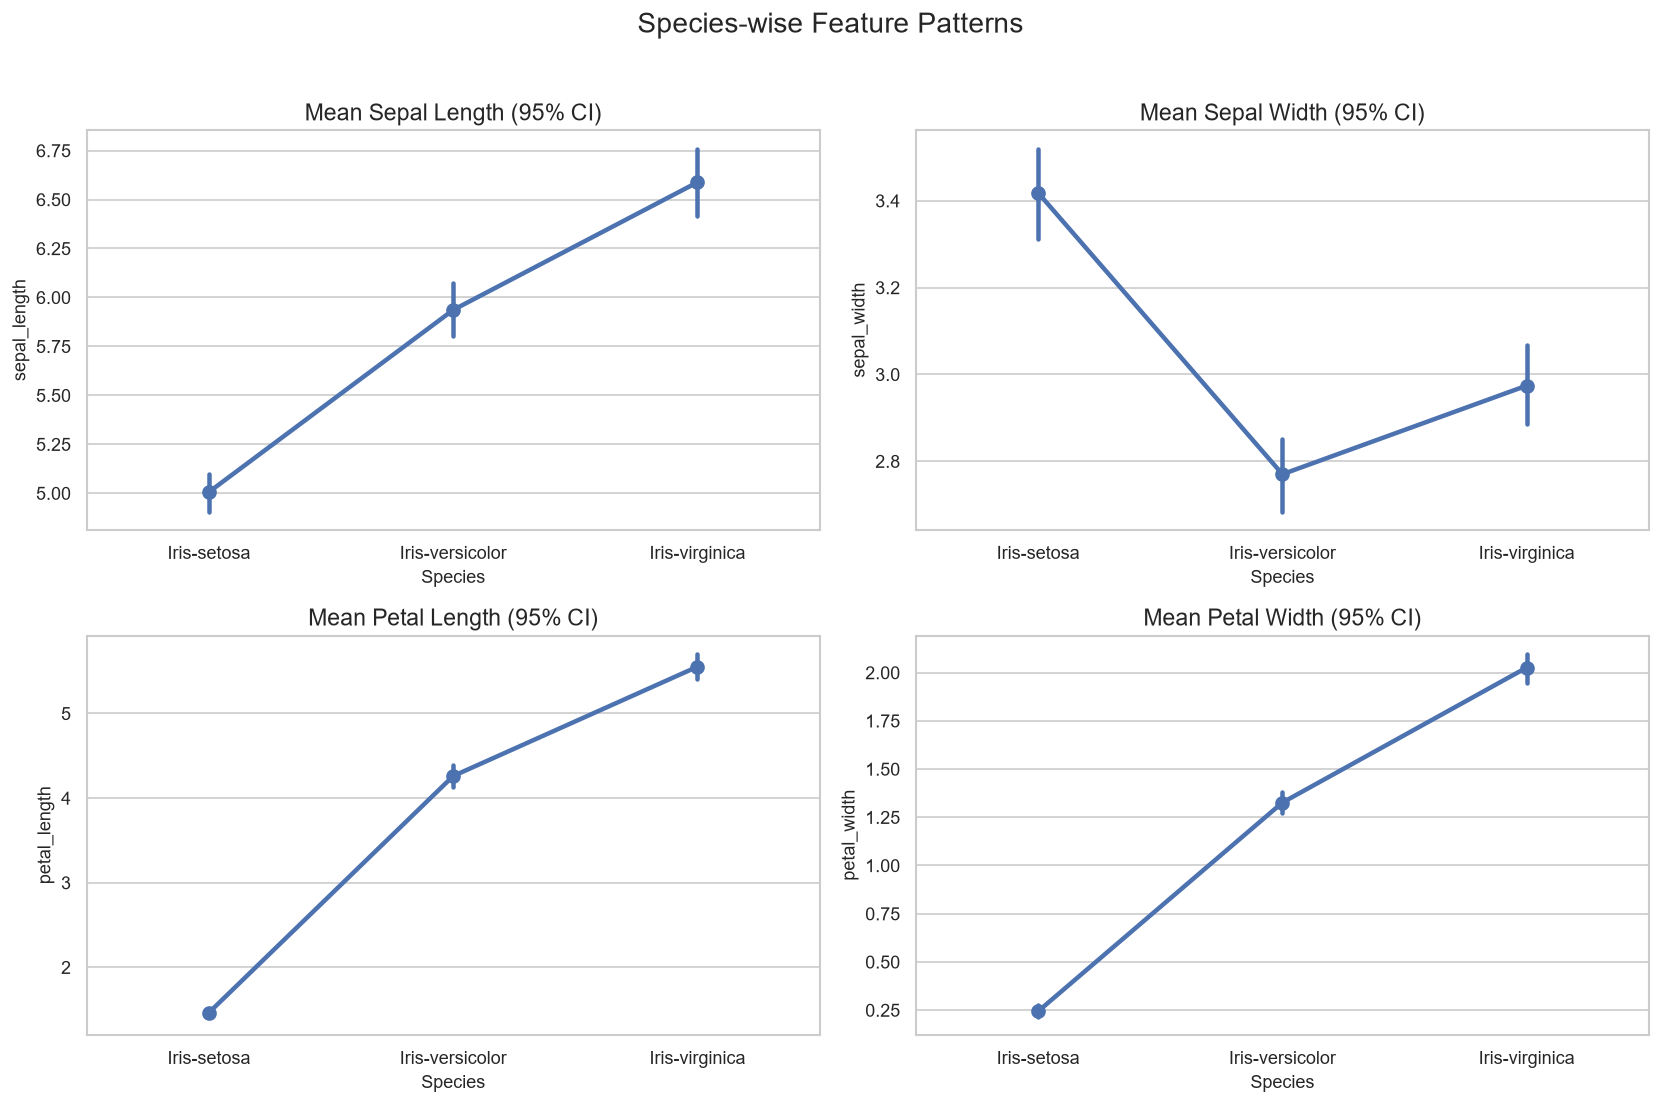

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, feature in zip(axes.flat, numeric_features):
    sns.pointplot(data=df, x="species", y=feature, errorbar=("ci", 95), ax=ax)
    ax.set_title(f"Mean {feature.replace('_', ' ').title()} (95% CI)")
    ax.set_xlabel("Species")
fig.suptitle("Species-wise Feature Patterns", fontsize=17, y=1.02)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "species_feature_patterns.png", dpi=300, bbox_inches="tight")
plt.show()

## 14. Automated analytical insights and report

In [14]:
insights = [
    "IRIS DATASET — EDA INSIGHTS",
    "=" * 50,
    f"Records: {len(df)}",
    f"Columns: {len(df.columns)}",
    f"Missing cells: {int(df.isna().sum().sum())}",
    f"Duplicate rows: {int(df.duplicated().sum())}",
    "",
    "SPECIES COUNTS"
]
for _, row in species_counts.iterrows():
    insights.append(f"{row['species']}: {row['count']} ({row['percentage']:.1f}%)")

insights += ["", "HIGHEST MEAN FEATURE BY SPECIES"]
for feature in numeric_features:
    means = df.groupby("species")[feature].mean()
    insights.append(f"{feature}: {means.idxmax()} ({means.max():.3f} cm)")

upper_corr = correlation.where(np.triu(np.ones(correlation.shape), k=1).astype(bool)).stack()
if not upper_corr.empty:
    strongest = upper_corr.abs().idxmax()
    insights += ["", "STRONGEST ABSOLUTE CORRELATION",
                 f"{strongest[0]} vs {strongest[1]}: {upper_corr.loc[strongest]:.3f}"]

report_text = "\n".join(insights)
print(report_text)
(REPORTS_DIR / "eda_insights.txt").write_text(report_text, encoding="utf-8")

IRIS DATASET — EDA INSIGHTS
Records: 150
Columns: 5
Missing cells: 0
Duplicate rows: 3

SPECIES COUNTS
Iris-setosa: 50 (33.3%)
Iris-versicolor: 50 (33.3%)
Iris-virginica: 50 (33.3%)

HIGHEST MEAN FEATURE BY SPECIES
sepal_length: Iris-virginica (6.588 cm)
sepal_width: Iris-setosa (3.418 cm)
petal_length: Iris-virginica (5.552 cm)
petal_width: Iris-virginica (2.026 cm)

STRONGEST ABSOLUTE CORRELATION
petal_length vs petal_width: 0.963


487

## 15. Export dataset summary and audit outputs

In [15]:
summary = pd.DataFrame({
    "metric": ["rows", "columns", "numeric_features", "species_categories",
               "missing_cells", "duplicate_rows"],
    "value": [len(df), len(df.columns), len(numeric_features),
              df["species"].nunique(), int(df.isna().sum().sum()),
              int(df.duplicated().sum())]
})
display(summary)
summary.to_csv(REPORTS_DIR / "dataset_summary.csv", index=False)

print("\nEDA outputs:")
for folder in [FIGURES_DIR, INTERACTIVE_DIR, REPORTS_DIR]:
    print(f"\n{folder.relative_to(PROJECT_ROOT)}/")
    for path in sorted(folder.iterdir()):
        if path.is_file():
            print(f"  {path.name} ({path.stat().st_size / 1024:.1f} KB)")

print("\nCompleted. No notebook file was created or saved by this workflow.")
print("Raw input file was not modified.")

,metric,value
0,rows,150
1,columns,5
2,numeric_features,4
3,species_categories,3
4,missing_cells,0
5,duplicate_rows,3



EDA outputs:

outputs\figures/
  boxplots.png (203.4 KB)
  correlation_heatmap.png (123.8 KB)
  feature_distributions.png (577.4 KB)
  pairplot.png (594.9 KB)
  species_distribution.png (69.7 KB)
  species_feature_patterns.png (329.0 KB)
  violin_plots.png (511.6 KB)

outputs\interactive/
  correlation_analysis.html (4749.7 KB)
  petal_length_boxplot.html (4754.2 KB)
  petal_relationship.html (4758.8 KB)
  sepal_length_distribution.html (4754.2 KB)
  species_comparison.html (4750.9 KB)

outputs\reports/
  data_quality_report.csv (0.2 KB)
  dataset_summary.csv (0.1 KB)
  descriptive_statistics.csv (0.5 KB)
  eda_insights.txt (0.5 KB)
  outlier_screening_report.csv (0.3 KB)
  species_distribution.csv (0.1 KB)
  species_statistical_summary.csv (1.0 KB)

Completed. No notebook file was created or saved by this workflow.
Raw input file was not modified.


# THE END